### Import Libraries and Data

In [ ]:
import pandas as pd
import altair as alt
from pathlib import Path
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/raw/ckd_raw.csv")

In [2]:
text_cols = df.select_dtypes(exclude="number").columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

In [3]:
train_df, test_df = train_test_split(
    df, test_size=0.25, random_state=522, stratify=df["class"]
)

In [4]:
labels = {
    "age": "Age (years)", "bp": "Blood pressure (mm Hg)",
    "sg": "Specific gravity", "al": "Albumin (0-5)", "su": "Sugar (0-5)",
    "rbc": "Red blood cells", "pc": "Pus cells", "pcc": "Pus cell clumps",
    "ba": "Bacteria", "bgr": "Blood glucose random (mg/dL)",
    "bu": "Blood urea (mg/dL)", "sc": "Serum creatinine (mg/dL)",
    "sod": "Sodium (mEq/L)", "pot": "Potassium (mEq/L)",
    "hemo": "Hemoglobin (g/dL)", "pcv": "Packed cell volume (%)",
    "wbcc": "White blood cell count (cells/cumm)",
    "rbcc": "Red blood cell count (millions/cmm)",
    "htn": "Hypertension", "dm": "Diabetes mellitus",
    "cad": "Coronary artery disease", "appet": "Appetite",
    "pe": "Pedal edema", "ane": "Anemia", "class": "Diagnosis",
}
numeric_cols = train_df.select_dtypes("number").columns.tolist()
categorical_cols = [c for c in text_cols if c != "class"]

In [5]:
print(train_df.shape)
print(train_df["class"].value_counts())
train_df.groupby("class")[numeric_cols].median().astype(int).T

(300, 25)
class
ckd       187
notckd    113
Name: count, dtype: int64


class,ckd,notckd
age,59,47
bp,80,70
sg,1,1
al,2,0
su,0,0
bgr,142,107
bu,53,33
sc,2,0
sod,136,142
pot,4,4


In [6]:
print(train_df.isna().sum().sort_values(ascending=False))

rbc      111
rbcc      98
wbcc      77
sod       66
pot       66
pcv       52
pc        48
hemo      38
su        37
sg        35
al        34
bgr       28
sc        10
bu        10
bp         8
age        6
pcc        4
ba         4
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64


In [7]:
missing = (
    train_df.isna().mean().mul(100).rename("pct_missing")
    .rename_axis("variable").reset_index()
    .assign(variable=lambda d: d["variable"].map(labels))
)
alt.Chart(missing).mark_bar().encode(
    x=alt.X("pct_missing:Q", title="Missing values (% of training rows)"),
    y=alt.Y("variable:N", sort="-x", title=None),
).properties(title="Missing values by variable", width=400)

alt.Chart(...)

In [8]:
# %% 2. Filter 1: drop features with more than 10% missing
pct_missing = train_df.drop(columns="class").isna().mean()
keep = pct_missing[pct_missing <= 0.1].index.tolist()

for c in keep:
    print(f"{labels[c]}: {train_df[c].dtype}")

Age (years): float64
Blood pressure (mm Hg): float64
Pus cell clumps: str
Bacteria: str
Blood glucose random (mg/dL): float64
Blood urea (mg/dL): float64
Serum creatinine (mg/dL): float64
Hypertension: str
Diabetes mellitus: str
Coronary artery disease: str
Appetite: str
Pedal edema: str
Anemia: str


In [9]:
to_number = {"yes": 1, "no": 0, "abnormal": 1, "normal": 0,
             "present": 1, "notpresent": 0, "poor": 1, "good": 0}
X_train = train_df[keep].replace(to_number).apply(pd.to_numeric)
y_train = (train_df["class"] == "ckd").astype(int)

In [10]:
strength = X_train.corrwith(y_train).sort_values(key=abs, ascending=False).round(2)

for c, r in strength.items():
    print(f"{labels[c]}: {r}")

Hypertension: 0.6
Diabetes mellitus: 0.55
Blood glucose random (mg/dL): 0.41
Appetite: 0.39
Blood urea (mg/dL): 0.39
Pedal edema: 0.37
Serum creatinine (mg/dL): 0.35
Anemia: 0.31
Blood pressure (mm Hg): 0.28
Pus cell clumps: 0.27
Coronary artery disease: 0.25
Age (years): 0.23
Bacteria: 0.18


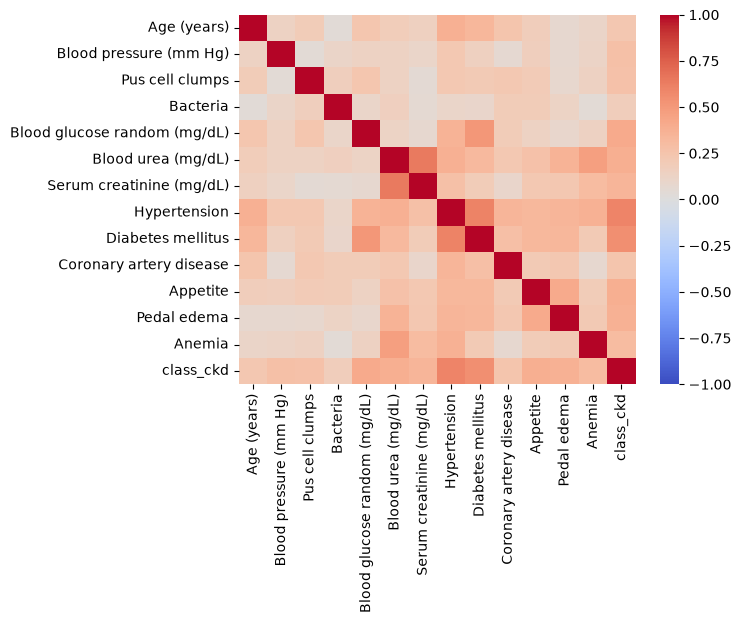

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = X_train.assign(class_ckd=y_train).corr().rename(index=labels, columns=labels)

sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

In [12]:
selected_4 = ["htn", "dm", "bgr", "appet"]

In [ ]:
from pathlib import Path

cols = selected_4 + ["class"]
Path("../data/processed").mkdir(parents=True, exist_ok=True)

train_df[cols].to_csv("../data/processed/ckd_train.csv", index=False)
test_df[cols].to_csv("../data/processed/ckd_test.csv", index=False)